In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('result_H=0.4_n=10.csv', names=['time', 'hsq', 'h_se'])
df

,time,hsq,h_se
0,2026-02-05T02:46:03,0.212981,0.090712
1,2026-02-05T02:47:14,0.300606,0.063637
2,2026-02-05T02:48:24,0.026336,0.051253
3,2026-02-05T02:49:32,0.083009,0.147176
4,2026-02-05T02:50:50,0.261975,0.103493
...,...,...,...
95,2026-02-05T04:42:35,0.223647,0.074329
96,2026-02-05T04:43:48,0.009277,0.031660
97,2026-02-05T04:44:56,0.077397,0.150744
98,2026-02-05T04:46:04,0.122931,0.084128


In [3]:
df['hsq'].var(), df['hsq'].mean(), df['h_se'].mean()

(0.007925644861064111, 0.14882861182336787, 0.10481878591102102)

In [4]:
df = pd.read_csv('/projects/ps-renlab2/sux002/cis_heritability/simulations/low_ld_gcta_result_eur_num_people_2026_3_05_low_ld.txt', sep='\t')
df.head()

,gene,parameter,hsq,hsq_se,hsq_p,su_hsq,su_hsq_se
0,1000G.EUR.18_59314289_1_0.050_300,1_0.05,0.059528,0.074394,1.821600e-01,0.013478,0.000275
1,1000G.EUR.18_59314289_1_0.100_300,1_0.1,-0.022672,0.056246,3.637100e-01,0.071121,0.040871
2,1000G.EUR.18_59314289_1_0.200_300,1_0.2,0.274915,0.127553,2.909400e-02,0.181111,0.073433
3,1000G.EUR.18_59314289_1_0.400_300,1_0.4,0.427982,0.126728,8.978500e-07,0.414208,0.074873
4,1000G.EUR.18_59314289_1_0.600_300,1_0.6,0.680428,0.152836,1.469400e-09,0.597905,0.489539


In [5]:
# split "parameter" like "1_0.05" -> n_snp="1", sim_h2="0.05"
df[["n_snp", "sim_h2"]] = df["parameter"].astype(str).str.split("_", n=1, expand=True)

# (optional) convert to numeric types
df["n_snp"] = pd.to_numeric(df["n_snp"], errors="coerce").astype("Int64")
df["sim_h2"] = pd.to_numeric(df["sim_h2"], errors="coerce")

In [6]:
df

,gene,parameter,hsq,hsq_se,hsq_p,su_hsq,su_hsq_se,n_snp,sim_h2
0,1000G.EUR.18_59314289_1_0.050_300,1_0.05,0.059528,0.074394,1.821600e-01,0.013478,0.000275,1,0.05
1,1000G.EUR.18_59314289_1_0.100_300,1_0.1,-0.022672,0.056246,3.637100e-01,0.071121,0.040871,1,0.10
2,1000G.EUR.18_59314289_1_0.200_300,1_0.2,0.274915,0.127553,2.909400e-02,0.181111,0.073433,1,0.20
3,1000G.EUR.18_59314289_1_0.400_300,1_0.4,0.427982,0.126728,8.978500e-07,0.414208,0.074873,1,0.40
4,1000G.EUR.18_59314289_1_0.600_300,1_0.6,0.680428,0.152836,1.469400e-09,0.597905,0.489539,1,0.60
...,...,...,...,...,...,...,...,...,...
745,1000G.EUR.7_150966895_20_0.100_300,20_0.1,0.089284,0.085375,1.022400e-01,0.047506,0.018025,20,0.10
746,1000G.EUR.7_150966895_20_0.200_300,20_0.2,0.150411,0.092135,1.582600e-02,0.049214,0.002616,20,0.20
747,1000G.EUR.7_150966895_20_0.400_300,20_0.4,0.485667,0.119652,8.708300e-11,0.251973,0.076723,20,0.40
748,1000G.EUR.7_150966895_20_0.600_300,20_0.6,0.760495,0.138702,4.996000e-16,0.345806,0.102887,20,0.60


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_gcta_vs_susie_box(df, n_snp, title_prefix="GCTA vs SuSiE: Normal",
                          gcta_color="skyblue", susie_color="lightgreen"):
    d = df[df["n_snp"] == n_snp].copy()
    if d.empty:
        raise ValueError(f"No rows found for n_snp={n_snp}")

    d["sim_h2"] = pd.to_numeric(d["sim_h2"], errors="coerce")
    d["hsq"] = pd.to_numeric(d["hsq"], errors="coerce")
    d["su_hsq"] = pd.to_numeric(d["su_hsq"], errors="coerce")

    h2_levels = sorted(d["sim_h2"].dropna().unique())
    gcta_data  = [d.loc[d["sim_h2"] == h2, "hsq"].dropna().to_numpy()    for h2 in h2_levels]
    susie_data = [d.loc[d["sim_h2"] == h2, "su_hsq"].dropna().to_numpy() for h2 in h2_levels]

    gcta_means  = [np.mean(x) if len(x) else np.nan for x in gcta_data]
    susie_means = [np.mean(x) if len(x) else np.nan for x in susie_data]

    x = np.arange(len(h2_levels))
    offset = 0.18
    pos_gcta  = x - offset
    pos_susie = x + offset
    width = 0.32

    fig, ax = plt.subplots(figsize=(10, 6))

    bp_gcta = ax.boxplot(gcta_data, positions=pos_gcta, widths=width,
                         patch_artist=True, labels=None)
    bp_susie = ax.boxplot(susie_data, positions=pos_susie, widths=width,
                          patch_artist=True, labels=None)

    # color the boxes
    for b in bp_gcta["boxes"]:
        b.set_facecolor(gcta_color)
    for b in bp_susie["boxes"]:
        b.set_facecolor(susie_color)

    # dashed red mean lines on each box
    for i in range(len(h2_levels)):
        if not np.isnan(gcta_means[i]):
            ax.hlines(gcta_means[i],
                      pos_gcta[i] - width/2, pos_gcta[i] + width/2,
                      colors="red", linestyles="--", linewidth=2)
        if not np.isnan(susie_means[i]):
            ax.hlines(susie_means[i],
                      pos_susie[i] - width/2, pos_susie[i] + width/2,
                      colors="red", linestyles="--", linewidth=2)

    ax.set_xticks(x)
    ax.set_xticklabels([f"{h2:g}" for h2 in h2_levels])
    ax.set_xlabel("Heritability")
    ax.set_ylabel("Heritability Estimates")
    ax.set_title(f"{title_prefix}, n_snp={n_snp}")

    # legend for the colored boxes
    ax.legend(handles=[
        Patch(facecolor=gcta_color, edgecolor="black", label="GCTA"),
        Patch(facecolor=susie_color, edgecolor="black", label="SuSiE"),
    ], loc="upper right")

    plt.tight_layout()
    plt.show()

# example:
# plot_gcta_vs_susie_box(df, n_snp=1)

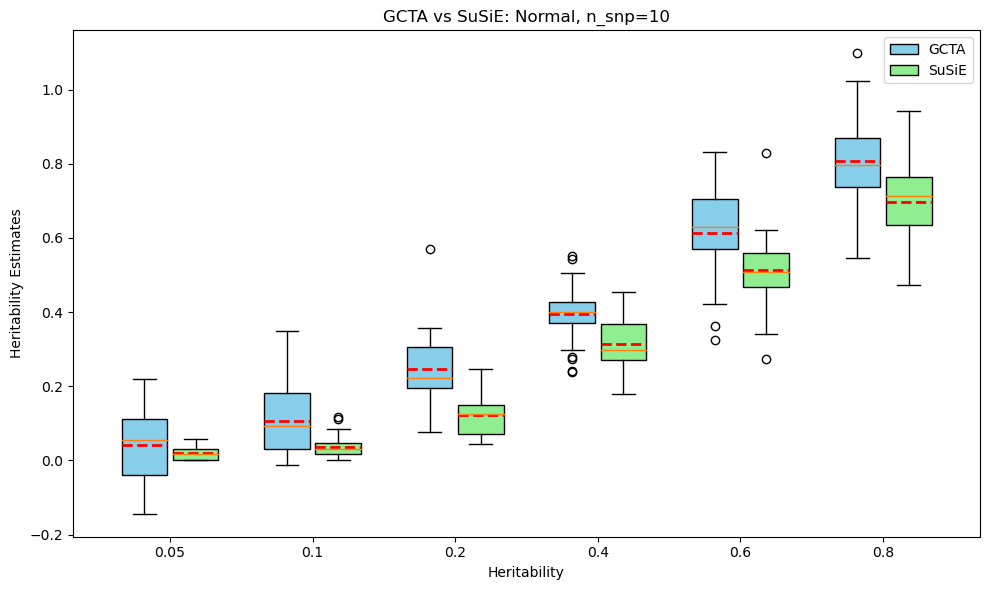

In [8]:
plot_gcta_vs_susie_box(df, 10, title_prefix="GCTA vs SuSiE: Normal")

In [9]:
def plot_gcta_vs_susie_box_percent_error(
    df, n_snp,
    title_prefix="GCTA vs SuSiE: Percent Error (Normal)",
    gcta_color="skyblue", susie_color="lightgreen",
    use_absolute=False,          # False: signed % error, True: absolute % error
    eps=1e-12                    # avoid division by zero when sim_h2 is 0
):
    d = df[df["n_snp"] == n_snp].copy()
    if d.empty:
        raise ValueError(f"No rows found for n_snp={n_snp}")

    # ensure numeric
    d["sim_h2"]  = pd.to_numeric(d["sim_h2"], errors="coerce")
    d["hsq"]     = pd.to_numeric(d["hsq"], errors="coerce")
    d["su_hsq"]  = pd.to_numeric(d["su_hsq"], errors="coerce")

    # percent error = 100 * (estimate - truth) / truth
    denom = d["sim_h2"].abs().clip(lower=eps)  # handles sim_h2==0 safely
    d["gcta_pe"]  = 100.0 * (d["hsq"]    - d["sim_h2"]) / denom
    d["susie_pe"] = 100.0 * (d["su_hsq"] - d["sim_h2"]) / denom

    if use_absolute:
        d["gcta_pe"] = d["gcta_pe"].abs()
        d["susie_pe"] = d["susie_pe"].abs()

    h2_levels = sorted(d["sim_h2"].dropna().unique())

    gcta_data  = [d.loc[d["sim_h2"] == h2, "gcta_pe"].dropna().to_numpy()  for h2 in h2_levels]
    susie_data = [d.loc[d["sim_h2"] == h2, "susie_pe"].dropna().to_numpy() for h2 in h2_levels]

    gcta_means  = [np.mean(x) if len(x) else np.nan for x in gcta_data]
    susie_means = [np.mean(x) if len(x) else np.nan for x in susie_data]

    x = np.arange(len(h2_levels))
    offset = 0.18
    pos_gcta  = x - offset
    pos_susie = x + offset
    width = 0.32

    fig, ax = plt.subplots(figsize=(10, 6))

    bp_gcta = ax.boxplot(gcta_data, positions=pos_gcta, widths=width,
                         patch_artist=True, labels=None)
    bp_susie = ax.boxplot(susie_data, positions=pos_susie, widths=width,
                          patch_artist=True, labels=None)

    for b in bp_gcta["boxes"]:
        b.set_facecolor(gcta_color)
    for b in bp_susie["boxes"]:
        b.set_facecolor(susie_color)

    # dashed red mean lines on each box
    for i in range(len(h2_levels)):
        if not np.isnan(gcta_means[i]):
            ax.hlines(gcta_means[i],
                      pos_gcta[i] - width/2, pos_gcta[i] + width/2,
                      colors="red", linestyles="--", linewidth=2)
        if not np.isnan(susie_means[i]):
            ax.hlines(susie_means[i],
                      pos_susie[i] - width/2, pos_susie[i] + width/2,
                      colors="red", linestyles="--", linewidth=2)

    ax.set_xticks(x)
    ax.set_xticklabels([f"{h2:g}" for h2 in h2_levels])
    ax.set_xlabel("True heritability (sim_h2)")

    if use_absolute:
        ax.set_ylabel("Absolute Percent Error (%)")
    else:
        ax.set_ylabel("Percent Error (%)")

    ax.set_title(f"{title_prefix}, n_snp={n_snp}")

    ax.legend(handles=[
        Patch(facecolor=gcta_color, edgecolor="black", label="GCTA"),
        Patch(facecolor=susie_color, edgecolor="black", label="SuSiE"),
    ], loc="upper right")

    # optional: reference line at 0% (perfect estimation)
    ax.axhline(0, color="black", linewidth=1, alpha=0.6)

    plt.tight_layout()
    plt.show()

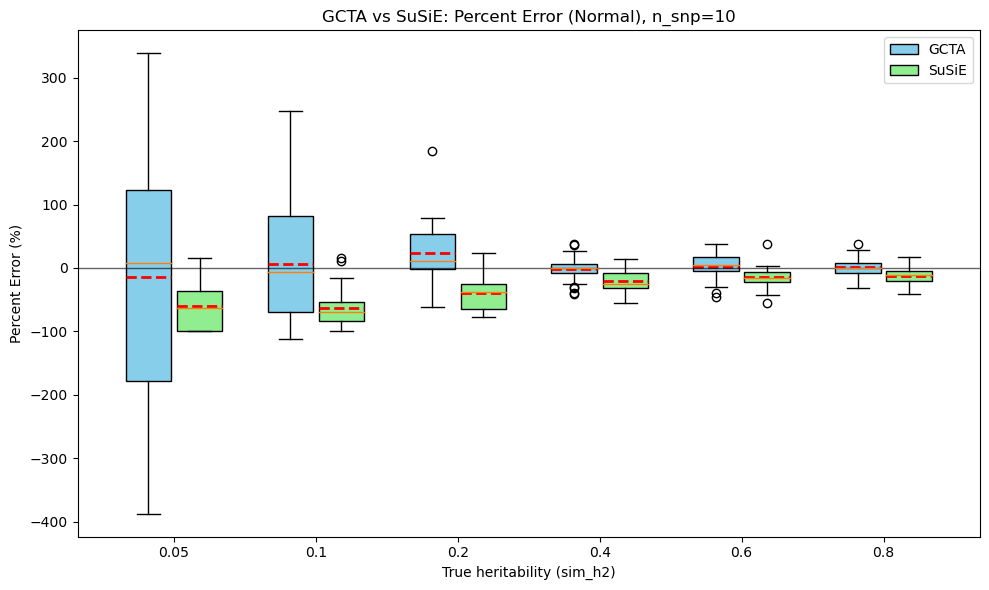

In [10]:
plot_gcta_vs_susie_box_percent_error(df, n_snp=10, use_absolute=False)

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_gcta_vs_susie_box_error(
    df, n_snp,
    title_prefix="GCTA vs SuSiE: Error",
    gcta_color="skyblue", susie_color="lightgreen",
    use_absolute=False   # False: signed error, True: absolute error
):
    d = df[df["n_snp"] == n_snp].copy()
    if d.empty:
        raise ValueError(f"No rows found for n_snp={n_snp}")

    # ensure numeric
    d["sim_h2"] = pd.to_numeric(d["sim_h2"], errors="coerce")
    d["hsq"] = pd.to_numeric(d["hsq"], errors="coerce")
    d["su_hsq"] = pd.to_numeric(d["su_hsq"], errors="coerce")

    # raw error = estimate - truth
    d["gcta_err"] = d["hsq"] - d["sim_h2"]
    d["susie_err"] = d["su_hsq"] - d["sim_h2"]

    if use_absolute:
        d["gcta_err"] = d["gcta_err"].abs()
        d["susie_err"] = d["susie_err"].abs()

    h2_levels = sorted(d["sim_h2"].dropna().unique())

    gcta_data = [d.loc[d["sim_h2"] == h2, "gcta_err"].dropna().to_numpy() for h2 in h2_levels]
    susie_data = [d.loc[d["sim_h2"] == h2, "susie_err"].dropna().to_numpy() for h2 in h2_levels]

    gcta_means = [np.mean(x) if len(x) else np.nan for x in gcta_data]
    susie_means = [np.mean(x) if len(x) else np.nan for x in susie_data]

    x = np.arange(len(h2_levels))
    offset = 0.18
    pos_gcta = x - offset
    pos_susie = x + offset
    width = 0.32

    fig, ax = plt.subplots(figsize=(10, 6))

    bp_gcta = ax.boxplot(
        gcta_data, positions=pos_gcta, widths=width,
        patch_artist=True, labels=None
    )
    bp_susie = ax.boxplot(
        susie_data, positions=pos_susie, widths=width,
        patch_artist=True, labels=None
    )

    for b in bp_gcta["boxes"]:
        b.set_facecolor(gcta_color)
    for b in bp_susie["boxes"]:
        b.set_facecolor(susie_color)

    # dashed red mean lines on each box
    for i in range(len(h2_levels)):
        if not np.isnan(gcta_means[i]):
            ax.hlines(
                gcta_means[i],
                pos_gcta[i] - width / 2, pos_gcta[i] + width / 2,
                colors="red", linestyles="--", linewidth=2
            )
        if not np.isnan(susie_means[i]):
            ax.hlines(
                susie_means[i],
                pos_susie[i] - width / 2, pos_susie[i] + width / 2,
                colors="red", linestyles="--", linewidth=2
            )

    ax.set_xticks(x)
    ax.set_xticklabels([f"{h2:g}" for h2 in h2_levels])
    ax.set_xlabel("True heritability (sim_h2)")

    if use_absolute:
        ax.set_ylabel("Absolute Error")
    else:
        ax.set_ylabel("Error (estimate - true)")

    ax.set_title(f"{title_prefix}, n_snp={n_snp}")

    ax.legend(handles=[
        Patch(facecolor=gcta_color, edgecolor="black", label="GCTA"),
        Patch(facecolor=susie_color, edgecolor="black", label="SuSiE"),
    ], loc="upper right")

    # reference line at 0 = perfect estimate
    ax.axhline(0, color="black", linewidth=1, alpha=0.6)

    plt.tight_layout()
    plt.show()

In [11]:
def calculate_analytical_se(susie_output_file):
    """
    Calculates SE using the 4th Moment Formula:
    Var(h2) = Sum( E[b^4] - (E[b^2])^2 )
    Assumes SuSiE output has 'post_mean' and 'post_sd' columns.
    """
    try:
        df = pd.read_csv(susie_output_file, sep=" ")
        
        # NOTE: Verify these column names match your R script output!
        if 'POSTERIOR' not in df.columns or 'POSTERIOR_SD' not in df.columns:
            print("WARNING: 'post_mean' or 'post_sd' columns missing. Cannot calc Analytical SE.")
            return np.nan

        mu = df['POSTERIOR']
        sigma = df['POSTERIOR_SD']
        
        # 2nd Moment: E[X^2] = mu^2 + sigma^2
        E_b2 = mu**2 + sigma**2
        
        # 4th Moment (Normal Assumption): E[X^4] = mu^4 + 6*mu^2*sigma^2 + 3*sigma^4
        E_b4 = mu**4 + 6 * (mu**2) * (sigma**2) + 3 * (sigma**4)
        
        # Variance of the squared term
        var_b2 = E_b4 - (E_b2**2)
        
        # Total SE (Sum of Variances, assuming independence)
        se_h2 = np.sqrt(np.sum(var_b2))
        return se_h2
        
    except Exception as e:
        print(f"Error in Analytical SE calc: {e}")
        return np.nan

In [12]:
import os
import pandas as pd
import numpy as np
from pathlib import Path

def process_folder_to_df(folder_path):
    results = []
    
    # Convert string path to a Path object
    path_obj = Path(folder_path)
    
    # Iterate over all files in the directory
    # If you only want .csv files, use .glob('*.csv') or .glob('*.txt')
    for file in path_obj.iterdir():
        if file.is_file():
            # Calculate the SE using your existing function
            se_value = calculate_analytical_se(str(file))
            
            df = pd.read_csv(str(file), sep=" ")
            est_h2 = np.sum(df['POSTERIOR']**2)
            
            # Append a dictionary with the filename and the result
            results.append({
                "file_name": file.name,
                "est_h2":est_h2, 
                "analytical_se": se_value
            })
            
    # Create the DataFrame
    return pd.DataFrame(results)

In [13]:
data = process_folder_to_df('/projects/ps-renlab2/sux002/output/tmpdir_1000G_eur_regular/sumstats')

FileNotFoundError: [Errno 2] No such file or directory: '/projects/ps-renlab2/sux002/output/tmpdir_1000G_eur_regular/sumstats'

In [ ]:
data.head()

,file_name,est_h2,analytical_se
0,1000G.EUR.11_89575072_1_0.400_300.txt,0.355014,0.069420
1,1000G.EUR.16_86827545_10_0.800_300.txt,0.370298,0.237660
2,1000G.EUR.11_15368460_1_0.200_300.txt,0.201438,0.051703
3,1000G.EUR.14_38121648_10_0.400_300.txt,0.122452,0.164467
4,1000G.EUR.5_121014793_20_0.800_300.txt,0.125110,0.174587


In [ ]:
df = data

In [ ]:
# 1. Split the file name by underscore
# We use .str.replace('.txt', '') first to remove the extension
parts = df['file_name'].str.replace('.txt', '', regex=False).str.split('_')

# 2. Extract the 'snp' column (3rd from the last)
# We cast to int for easier sorting/plotting later
df['snp'] = parts.str[-3].astype(int)

# 3. Extract the 'true_her' column (2nd from the last)
# We cast to float for numeric analysis
df['true_her'] = parts.str[-2].astype(float)

# 4. (Optional) Sort the dataframe so it's readable
df = df.sort_values(by=['snp', 'true_her']).reset_index(drop=True)

In [ ]:
parts

0        [1000G.EUR.11, 89575072, 1, 0.400, 300]
1       [1000G.EUR.16, 86827545, 10, 0.800, 300]
2        [1000G.EUR.11, 15368460, 1, 0.200, 300]
3       [1000G.EUR.14, 38121648, 10, 0.400, 300]
4       [1000G.EUR.5, 121014793, 20, 0.800, 300]
                          ...                   
1636     [1000G.EUR.14, 38121648, 3, 0.050, 300]
1637    [1000G.EUR.21, 32423328, 10, 0.600, 300]
1638     [1000G.EUR.19, 43378004, 3, 0.400, 300]
1639     [1000G.EUR.6, 103905332, 3, 0.050, 300]
1640    [1000G.EUR.19, 43367560, 20, 0.800, 300]
Name: file_name, Length: 1641, dtype: object

In [ ]:
# Wrap each condition in () to ensure they are evaluated before the &
df_1_005 = df[(df['snp'] == 1) & (df['true_her'] == 0.05)]
df_5_005 = df[(df['snp'] == 5) & (df['true_her'] == 0.05)]
df_10_005 = df[(df['snp'] == 10) & (df['true_her'] == 0.05)]
df_1_01 = df[(df['snp'] == 1) & (df['true_her'] == 0.1)]
df_5_01 = df[(df['snp'] == 5) & (df['true_her'] == 0.1)]
df_10_01 = df[(df['snp'] == 10) & (df['true_her'] == 0.1)]

In [ ]:
df_1_06 = df[(df['snp'] == 1) & (df['true_her'] == 0.6)]
df_5_06 = df[(df['snp'] == 5) & (df['true_her'] == 0.6)]
df_10_06 = df[(df['snp'] == 10) & (df['true_her'] == 0.6)]

In [ ]:
df_1_04 = df[(df['snp'] == 1) & (df['true_her'] == 0.4)]
df_5_04 = df[(df['snp'] == 5) & (df['true_her'] == 0.4)]
df_10_04 = df[(df['snp'] == 10) & (df['true_her'] == 0.4)]

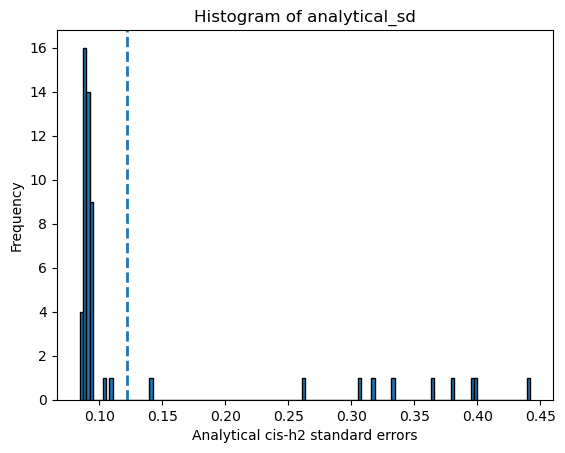

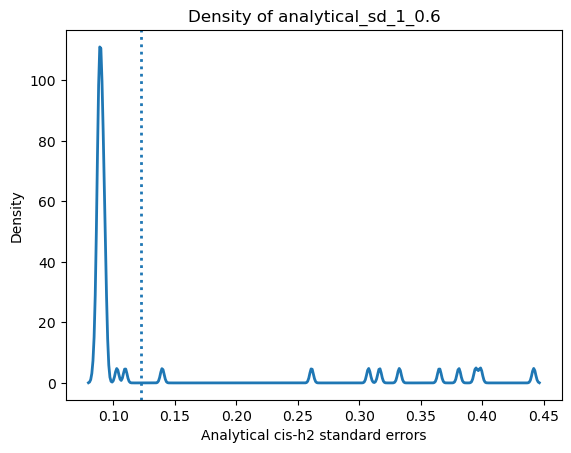

sd(susie_est) = 0.12206963510952151


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Data (R c(...) -> Python lists / numpy arrays)
susie_est = np.array(df_1_06['est_h2'])
analytical_sd = np.array(df_1_06['analytical_se'])

# R's sd() uses sample SD (ddof=1)
emp_sd = np.std(susie_est, ddof=1)

# 1) Histogram + vertical line
plt.figure()
plt.hist(analytical_sd, bins="auto", edgecolor="black")
plt.axvline(emp_sd, linestyle="--", linewidth=2)
plt.xlabel("Analytical cis-h2 standard errors")
plt.ylabel("Frequency")
plt.title("Histogram of analytical_sd")
plt.show()

# 2) Density plot (simple Gaussian KDE, no scipy needed)
n = analytical_sd.size
std = np.std(analytical_sd, ddof=1)
iqr = np.percentile(analytical_sd, 75) - np.percentile(analytical_sd, 25)
sigma = min(std, iqr / 1.34) if iqr > 0 else std
bw = 0.9 * sigma * n ** (-1 / 5) if sigma > 0 else 1e-3  # Silverman's rule

x = np.linspace(analytical_sd.min() - 3*bw, analytical_sd.max() + 3*bw, 400)
kde = np.mean(
    np.exp(-0.5 * ((x[:, None] - analytical_sd[None, :]) / bw) ** 2) / (bw * np.sqrt(2 * np.pi)),
    axis=1
)

plt.figure()
plt.plot(x, kde, linewidth=2)  # (R: col="darkblue", lwd=2) -> default color unless you want to set it
plt.axvline(emp_sd, linestyle=":", linewidth=2)  # (R: lty=4)
plt.xlabel("Analytical cis-h2 standard errors")
plt.ylabel("Density")
plt.title("Density of analytical_sd_1_0.6")
plt.show()

print("sd(susie_est) =", emp_sd)

In [48]:
df = pd.read_csv('/projects/ps-renlab2/sux002/cis_heritability/simulations/effect_size_gcta_result_eur_2026_03_13_es.txt', sep='\t')
df = df.rename(columns={"ncausal": "n_snp"})
df = df.rename(columns={"h2": "sim_h2"})
df = df[df['effect_dist']=='normal']
df.head()

,gene,n_snp,sim_h2,effect_dist,hsq,hsq_se,hsq_p,su_hsq,su_hsq_se
0,1000G.EUR.14_57600227_1_0.050_normal_300,1,0.05,normal,-0.014314,0.061222,4.148300e-01,0.000000,0.000000
3,1000G.EUR.14_57600227_1_0.100_normal_300,1,0.10,normal,0.101438,0.093409,1.297400e-01,0.125499,0.080550
6,1000G.EUR.14_57600227_1_0.200_normal_300,1,0.20,normal,0.177124,0.101930,2.307200e-02,0.218226,0.057556
9,1000G.EUR.14_57600227_1_0.400_normal_300,1,0.40,normal,0.408710,0.142731,6.524100e-04,0.338303,0.065802
12,1000G.EUR.14_57600227_1_0.600_normal_300,1,0.60,normal,0.535773,0.137414,1.016400e-07,0.588829,0.088380


In [49]:
df.head()

,gene,n_snp,sim_h2,effect_dist,hsq,hsq_se,hsq_p,su_hsq,su_hsq_se
0,1000G.EUR.14_57600227_1_0.050_normal_300,1,0.05,normal,-0.014314,0.061222,4.148300e-01,0.000000,0.000000
3,1000G.EUR.14_57600227_1_0.100_normal_300,1,0.10,normal,0.101438,0.093409,1.297400e-01,0.125499,0.080550
6,1000G.EUR.14_57600227_1_0.200_normal_300,1,0.20,normal,0.177124,0.101930,2.307200e-02,0.218226,0.057556
9,1000G.EUR.14_57600227_1_0.400_normal_300,1,0.40,normal,0.408710,0.142731,6.524100e-04,0.338303,0.065802
12,1000G.EUR.14_57600227_1_0.600_normal_300,1,0.60,normal,0.535773,0.137414,1.016400e-07,0.588829,0.088380


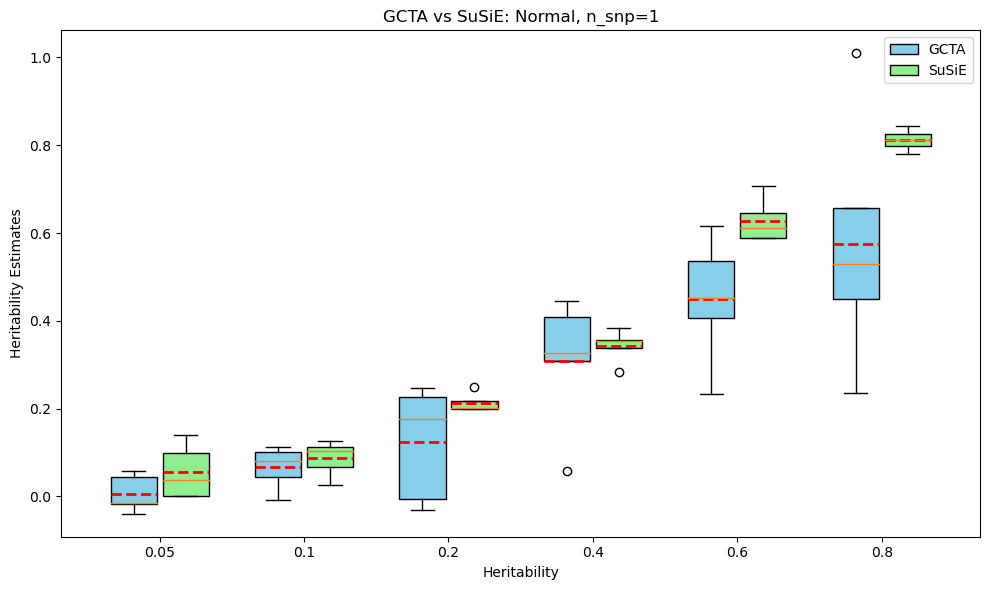

In [56]:
plot_gcta_vs_susie_box(df, 1, title_prefix="GCTA vs SuSiE: Normal")

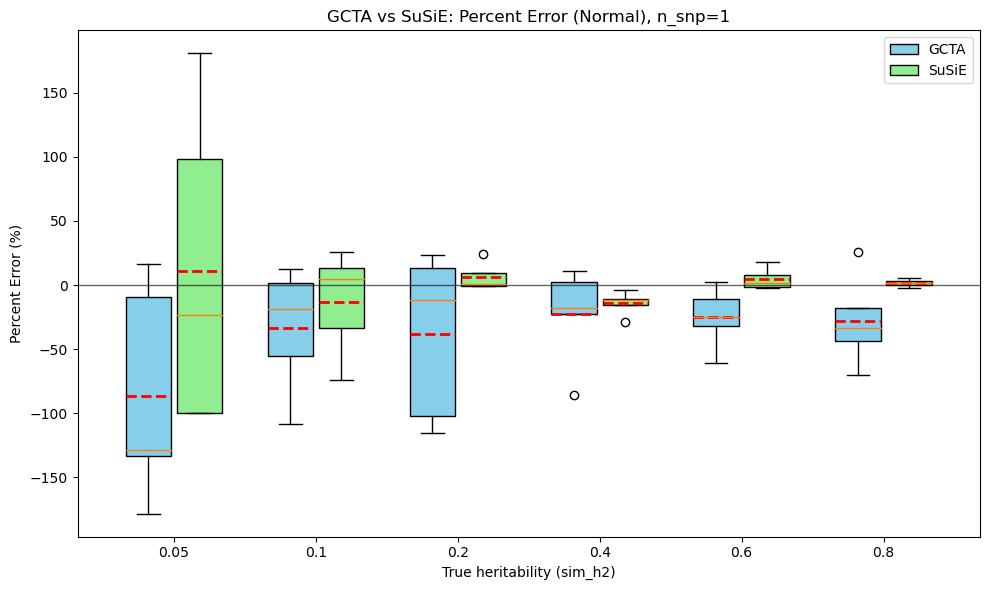

In [57]:
plot_gcta_vs_susie_box_percent_error(df, n_snp=1, use_absolute=False)

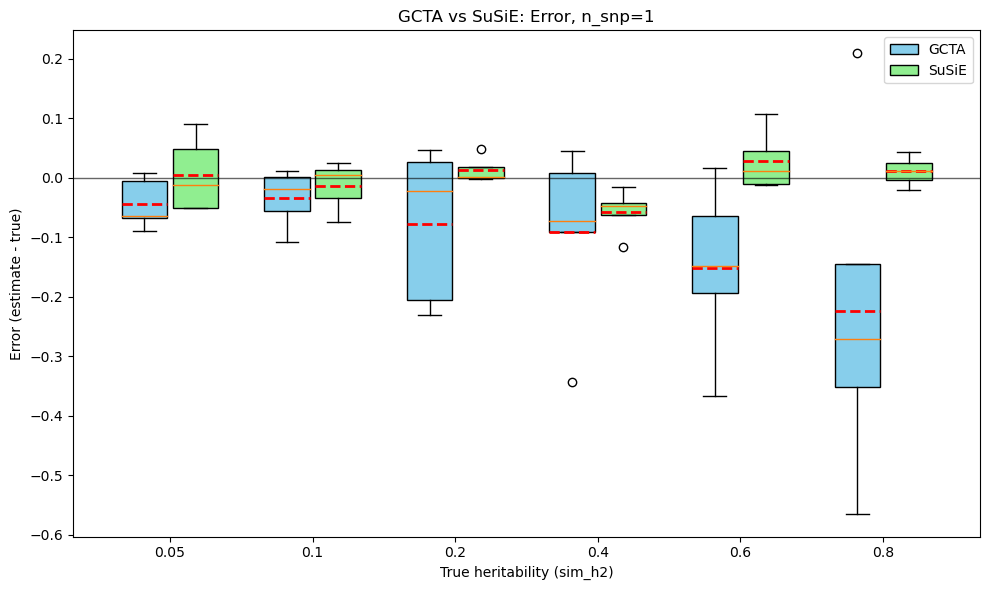

In [58]:
plot_gcta_vs_susie_box_error(df, n_snp=1, use_absolute=False)